# VIBE2 FBCCA + KNN evaluation

This notebook uses the same `four_106_ssvep` input and FBCCA settings as `fbcca.ipynb`. Each trial is converted into four FBCCA scores, then a KNN classifier is evaluated without mixing training and test samples.

Frequency/label mapping: `0 -> 15 Hz`, `1 -> 12 Hz`, `2 -> 10 Hz`, `3 -> 8.57 Hz`.

In [36]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import cheby1, cheb1ord, filtfilt
from sklearn.cross_decomposition import CCA
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [37]:
txt = 'four_2_ssvep'
eeg_trials = np.load(f'data/eeg_trials_{txt}.npy', allow_pickle=True)
eeg_labels = np.load(f'data/eeg_labels_{txt}.npy')

list_freqs = np.array([15.0, 12.0, 10.0])
fs = 250
num_fbs = 5
num_harms = 1
len_shift_s = 0.5
len_gaze_s = 1.4
knn_neighbors = 4
random_state = 42

print('EEG shape:', eeg_trials.shape)
print('Labels:', np.unique(eeg_labels, return_counts=True))

EEG shape: (152, 8, 497)
Labels: (array([0, 1, 2]), array([38, 84, 30]))


## FBCCA feature extraction

The first 0.5 s is discarded and the following 1.4 s is used. The four weighted squared-correlation scores are the KNN input features. Filtering is calculated once per filter bank and reused for all target frequencies.

In [38]:
def filterbank(eeg, fs, idx_fb):
    eeg = np.asarray(eeg, dtype=np.float64)
    if idx_fb < 1 or idx_fb > 10:
        raise ValueError('Filter index must be 1 <= idx_fb <= 10')

    passband = np.array([6, 14, 22, 30, 38, 46, 54, 62, 70, 78])
    stopband = np.array([4, 10, 16, 24, 32, 40, 48, 56, 64, 72])
    nyquist = fs / 2
    wp = [passband[idx_fb - 1] / nyquist, 90 / nyquist]
    ws = [stopband[idx_fb - 1] / nyquist, 100 / nyquist]
    order, wn = cheb1ord(wp, ws, 3, 40)
    b, a = cheby1(order, 0.5, wn, btype='bandpass')
    return filtfilt(b, a, eeg, axis=1)


def fbcca_features_single_trial(testdata, list_freqs, fs, num_harms, num_fbs):
    start = round(len_shift_s * fs)
    end = start + round(len_gaze_s * fs)
    testdata = np.asarray(testdata, dtype=np.float64)[:, start:end]
    if testdata.shape[1] != round(len_gaze_s * fs):
        raise ValueError(f'Trial is too short: {testdata.shape[1]} samples after slicing')

    timepoints = np.arange(testdata.shape[1]) / fs
    fb_coefs = np.array([i ** (-1.25) + 0.25 for i in range(1, num_fbs + 1)])
    filtered_banks = [filterbank(testdata, fs, i) for i in range(1, num_fbs + 1)]
    scores = []

    for freq in list_freqs:
        references = []
        for harmonic in range(1, num_harms + 1):
            references.append(np.sin(2 * np.pi * harmonic * freq * timepoints))
            references.append(np.cos(2 * np.pi * harmonic * freq * timepoints))
        reference = np.asarray(references).T

        correlations = []
        for eeg_fb in filtered_banks:
            good_channels = np.std(eeg_fb, axis=1) > 1e-8
            eeg_good = eeg_fb[good_channels]
            if eeg_good.shape[0] == 0:
                correlations.append(0.0)
                continue
            u, v = CCA(n_components=1).fit_transform(eeg_good.T, reference)
            corr = np.corrcoef(u[:, 0], v[:, 0])[0, 1]
            correlations.append(0.0 if np.isnan(corr) else corr)

        scores.append(np.sum(fb_coefs * np.square(correlations)))

    return np.asarray(scores, dtype=np.float64)

In [39]:
fbcca_features = np.stack([
    fbcca_features_single_trial(trial, list_freqs, fs, num_harms, num_fbs)
    for trial in eeg_trials
])
fbcca_predictions = np.argmax(fbcca_features, axis=1)
fbcca_accuracy = accuracy_score(eeg_labels, fbcca_predictions)

print('FBCCA feature shape:', fbcca_features.shape)
print(f'Pure FBCCA accuracy: {fbcca_accuracy:.4f} ({np.sum(fbcca_predictions == eeg_labels)}/{len(eeg_labels)})')
print('Pure FBCCA confusion matrix:')
print(confusion_matrix(eeg_labels, fbcca_predictions, labels=[0, 1, 2, 3]))

FBCCA feature shape: (152, 3)
Pure FBCCA accuracy: 0.7171 (109/152)
Pure FBCCA confusion matrix:
[[36  1  1  0]
 [24 55  5  0]
 [ 5  7 18  0]
 [ 0  0  0  0]]


## Stratified 80/20 holdout

Feature standardization is fitted only on the training set through a pipeline. Pure FBCCA is also measured on exactly the same held-out trials.

In [40]:
indices = np.arange(len(eeg_labels))
train_idx, test_idx = train_test_split(
    indices, test_size=0.2, random_state=random_state, stratify=eeg_labels
)

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=knn_neighbors),
)
knn.fit(fbcca_features[train_idx], eeg_labels[train_idx])
knn_train_predictions = knn.predict(fbcca_features[train_idx])
knn_test_predictions = knn.predict(fbcca_features[test_idx])

fbcca_holdout_accuracy = accuracy_score(eeg_labels[test_idx], fbcca_predictions[test_idx])
knn_train_accuracy = accuracy_score(eeg_labels[train_idx], knn_train_predictions)
knn_test_accuracy = accuracy_score(eeg_labels[test_idx], knn_test_predictions)

print(f'Train/test size: {len(train_idx)}/{len(test_idx)}')
print(f'Pure FBCCA on the same test set: {fbcca_holdout_accuracy:.4f}')
print(f'FBCCA-KNN train accuracy:       {knn_train_accuracy:.4f}')
print(f'FBCCA-KNN test accuracy:        {knn_test_accuracy:.4f}')
print('FBCCA-KNN test confusion matrix:')
print(confusion_matrix(eeg_labels[test_idx], knn_test_predictions, labels=[0, 1, 2, 3]))

Train/test size: 121/31
Pure FBCCA on the same test set: 0.6452
FBCCA-KNN train accuracy:       0.7769
FBCCA-KNN test accuracy:        0.7419
FBCCA-KNN test confusion matrix:
[[ 6  1  1  0]
 [ 3 13  1  0]
 [ 0  2  4  0]
 [ 0  0  0  0]]


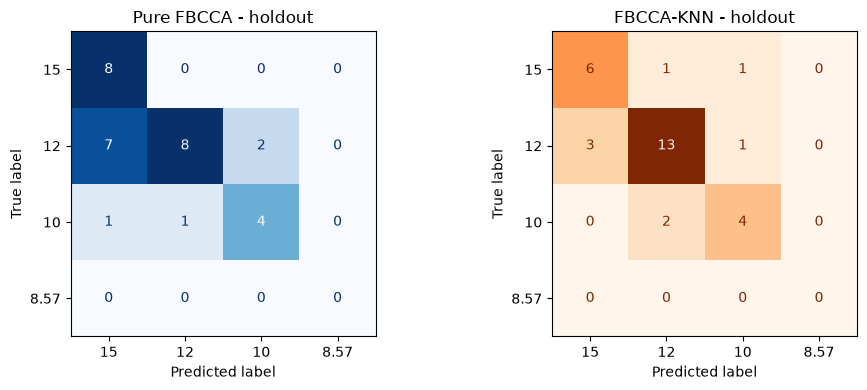

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
display_labels = ['15', '12', '10', '8.57']
ConfusionMatrixDisplay.from_predictions(
    eeg_labels[test_idx], fbcca_predictions[test_idx],
    labels=[0, 1, 2, 3], display_labels=display_labels,
    cmap='Blues', colorbar=False, ax=axes[0]
)
axes[0].set_title('Pure FBCCA - holdout')
ConfusionMatrixDisplay.from_predictions(
    eeg_labels[test_idx], knn_test_predictions,
    labels=[0, 1, 2, 3], display_labels=display_labels,
    cmap='Oranges', colorbar=False, ax=axes[1]
)
axes[1].set_title('FBCCA-KNN - holdout')
plt.tight_layout()
plt.show()

## Five-fold cross-validation

The pipeline prevents scaler leakage. Each trial contributes exactly one feature vector, so overlapping-window leakage is not introduced.

In [42]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
knn_cv_scores = cross_val_score(knn, fbcca_features, eeg_labels, cv=cv, scoring='accuracy')
fbcca_cv_scores = np.array([
    accuracy_score(eeg_labels[test], fbcca_predictions[test])
    for _, test in cv.split(fbcca_features, eeg_labels)
])

print('Pure FBCCA fold scores:', np.round(fbcca_cv_scores, 4))
print(f'Pure FBCCA fold mean:   {fbcca_cv_scores.mean():.4f} +/- {fbcca_cv_scores.std():.4f}')
print('FBCCA-KNN fold scores: ', np.round(knn_cv_scores, 4))
print(f'FBCCA-KNN fold mean:    {knn_cv_scores.mean():.4f} +/- {knn_cv_scores.std():.4f}')

Pure FBCCA fold scores: [0.5806 0.8065 0.6333 0.8    0.7667]
Pure FBCCA fold mean:   0.7174 +/- 0.0927
FBCCA-KNN fold scores:  [0.6452 0.7097 0.6667 0.7333 0.7333]
FBCCA-KNN fold mean:    0.6976 +/- 0.0358


## Exploratory neighbor sweep

This is exploratory tuning on the same five folds. The best value below must not be reported as an independent test result; a separate session is needed for final validation.

In [43]:
neighbor_results = []
for neighbors in range(1, 11):
    candidate = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=neighbors),
    )
    scores = cross_val_score(candidate, fbcca_features, eeg_labels, cv=cv, scoring='accuracy')
    neighbor_results.append((neighbors, scores.mean(), scores.std()))

for neighbors, mean_score, std_score in neighbor_results:
    print(f'k={neighbors:2d}: {mean_score:.4f} +/- {std_score:.4f}')

best_neighbors, best_mean, best_std = max(neighbor_results, key=lambda row: row[1])
print(f'Exploratory best: k={best_neighbors}, CV={best_mean:.4f} +/- {best_std:.4f}')

k= 1: 0.6643 +/- 0.0531
k= 2: 0.6185 +/- 0.0130
k= 3: 0.6641 +/- 0.0882
k= 4: 0.6976 +/- 0.0358
k= 5: 0.7572 +/- 0.0774
k= 6: 0.7174 +/- 0.0690
k= 7: 0.7372 +/- 0.0706
k= 8: 0.7308 +/- 0.0738
k= 9: 0.7310 +/- 0.0936
k=10: 0.7372 +/- 0.0822
Exploratory best: k=5, CV=0.7572 +/- 0.0774


## Interpretation

For this recording, fixed `k=4` FBCCA-KNN does not show a stable improvement over direct FBCCA. The single 80/20 holdout is worse for KNN, while five-fold means are close. Any neighbor selected by the sweep must be validated on another recording session before deployment.